# PRCP-1020 — HOUSE PRICE PREDICTION

## Project Overview
This project analyzes the Ames, Iowa housing dataset and builds regression models to predict `SalePrice`.

## Project Tasks
- **Task 1 — Data Analysis:** Perform complete data understanding, data-quality checks and exploratory data analysis.
- **Task 2(a) — House Price Prediction:** Build and compare robust regression models and recommend the best production model.
- **Task 2(b) — Feature–Price Relationship:** Determine how important house characteristics are associated with selling price.
- **Task 3 — Customer Suggestions:** Use the model to support budget-based house selection and customer requirements.

## Business Question
> **Which house characteristics have the strongest relationship with selling price, and can those characteristics be used to predict a reasonable house price?**

## Key Definitions
- **Feature:** An input characteristic used to explain or predict house price.
- **Target:** The value being predicted — `SalePrice`.
- **EDA:** Exploratory Data Analysis; understanding data using statistics and visualizations.
- **Feature Engineering:** Creating useful predictors from existing columns.
- **Regression:** Supervised learning where the target is a continuous numeric value.
- **R²:** Higher is better; measures the proportion of price variation explained by the model.
- **MAE:** Lower is better; average absolute prediction error in dollars.
- **RMSE:** Lower is better; penalizes large prediction errors more strongly.

## 1. IMPORT LIBRARIES

In [1]:
# 1.1 IMPORT LIBRARIES
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully.")
print("Random state:", RANDOM_STATE)


All libraries imported successfully.
Random state: 42


## 2. DATA LOADING

We will automatically search the project folder for `data.csv`. This makes the notebook easier to run in different locations.

In [3]:
# 2.1 LOAD DATASET

# The notebook searches common project locations so it can be run from
# the project folder, the notebook folder, or a parent folder.
possible_paths = [
    "dataset/data/data.csv",
    "dataset/data.csv",
    "data/data.csv",
    "data.csv",
    "../dataset/data/data.csv",
    "../dataset/data.csv",
    "../data/data.csv"
]

# Add any data.csv found below the current working directory.
possible_paths += glob.glob("**/data.csv", recursive=True)

data_path = next((p for p in dict.fromkeys(possible_paths) if os.path.isfile(p)), None)

if data_path is None:
    raise FileNotFoundError(
        "data.csv was not found. Place the project dataset at "
        "House_Price_Prediction/dataset/data/data.csv (or another searched location)."
    )

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. DATASET OVERVIEW

The project brief describes an Ames, Iowa housing dataset containing many explanatory variables. The prediction target is `SalePrice`.

### What we inspect
1. Number of observations and variables
2. Data types
3. Missing values
4. Duplicate records
5. Numerical and categorical variables
6. Basic statistical distribution

In [4]:
# 3.1 BASIC DATA UNDERSTANDING

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDescriptive statistics:")
display(df.describe(include="all").T.head(30))

Rows: 1460
Columns: 81

Data types:


,Data Type
Id,int64
MSSubClass,int64
MSZoning,str
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,str
SaleCondition,str



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.0,NaN,NaN,NaN,730.5,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,NaN,NaN,NaN,56.89726,42.300571,20.0,20.0,50.0,70.0,190.0
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.0,NaN,NaN,NaN,70.049958,24.284752,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,NaN,NaN,NaN,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.5,215245.0
Street,1460,2,Pave,1454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Alley,91,2,Grvl,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotShape,1460,4,Reg,925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LandContour,1460,4,Lvl,1311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Utilities,1460,2,AllPub,1459,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing Count,Missing %
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


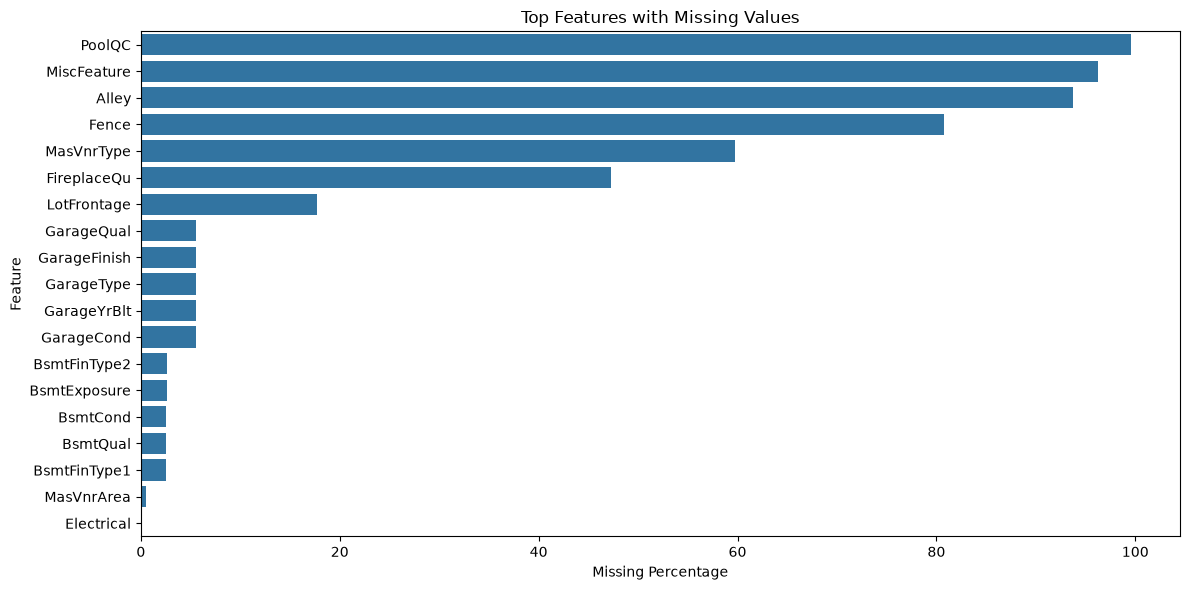

INSIGHT: Missingness must be handled carefully because different columns represent different types of information.


In [5]:
# 3.2 MISSING VALUES REPORT

missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_pct
})

display(missing_report[missing_report["Missing Count"] > 0].head(30))

plt.figure(figsize=(12,6))
top_missing = missing_report[missing_report["Missing Count"] > 0].head(20)
sns.barplot(x=top_missing["Missing %"], y=top_missing.index)
plt.title("Top Features with Missing Values")
plt.xlabel("Missing Percentage")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("INSIGHT: Missingness must be handled carefully because different columns represent different types of information.")

Duplicate rows: 0

Target summary:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

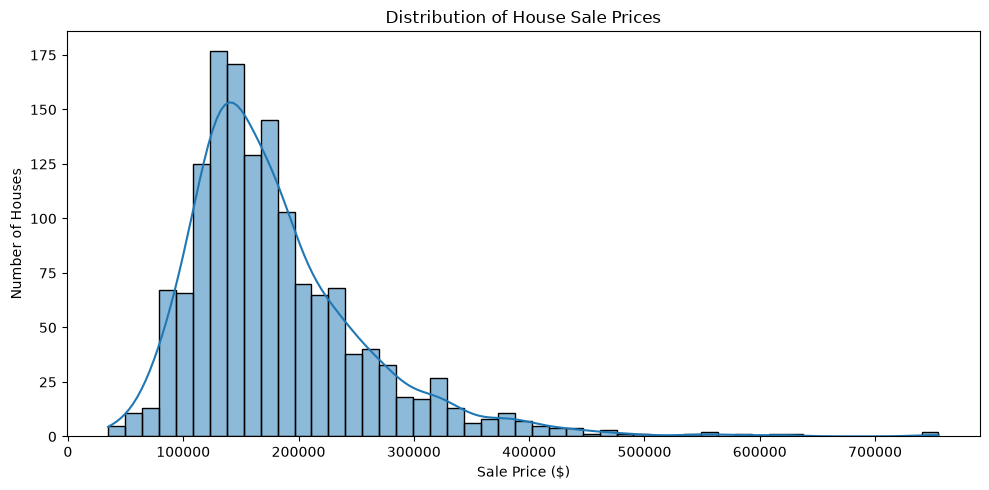

INSIGHT: The target distribution should be checked for skewness and extreme values before modeling.


In [6]:
# 3.3 DUPLICATES AND TARGET CHECK

print("Duplicate rows:", df.duplicated().sum())

if "SalePrice" not in df.columns:
    raise ValueError("SalePrice column was not found. Check the dataset.")

print("\nTarget summary:")
display(df["SalePrice"].describe())

plt.figure(figsize=(10,5))
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")
plt.tight_layout()
plt.show()

print("INSIGHT: The target distribution should be checked for skewness and extreme values before modeling.")

## 4. TASK 1 — EXPLORATORY DATA ANALYSIS

### Objective
Prepare a complete data-analysis report by understanding the dataset, checking data quality and visually investigating the variables related to house price.

### Analysis covered
1. Dataset dimensions and data types
2. Missing-value analysis
3. Duplicate and target checks
4. Distribution of `SalePrice`
5. Numerical correlation analysis
6. Feature-vs-price visualizations
7. Quality, neighborhood and area analysis

### Insight
EDA helps identify important price drivers, data-quality problems, skewness and possible outliers before model training.

Top positive correlations with SalePrice:


,Correlation
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


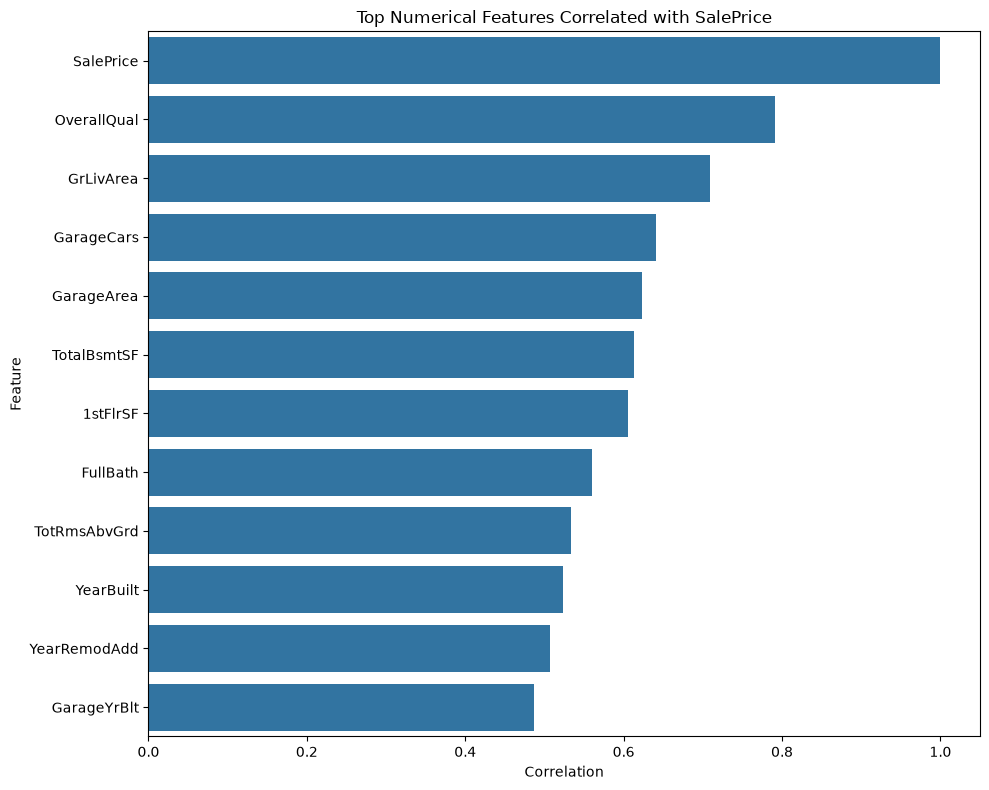

INSIGHT: Features near the top are strong candidates for further investigation, but correlation alone is not enough for final feature selection.


In [7]:
# 4.1 NUMERICAL CORRELATION WITH SALEPRICE

numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)

print("Top positive correlations with SalePrice:")
display(corr.head(15).to_frame("Correlation"))

plt.figure(figsize=(10,8))
top_corr = corr.head(12)
sns.barplot(x=top_corr.values, y=top_corr.index)
plt.title("Top Numerical Features Correlated with SalePrice")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("INSIGHT: Features near the top are strong candidates for further investigation, but correlation alone is not enough for final feature selection.")

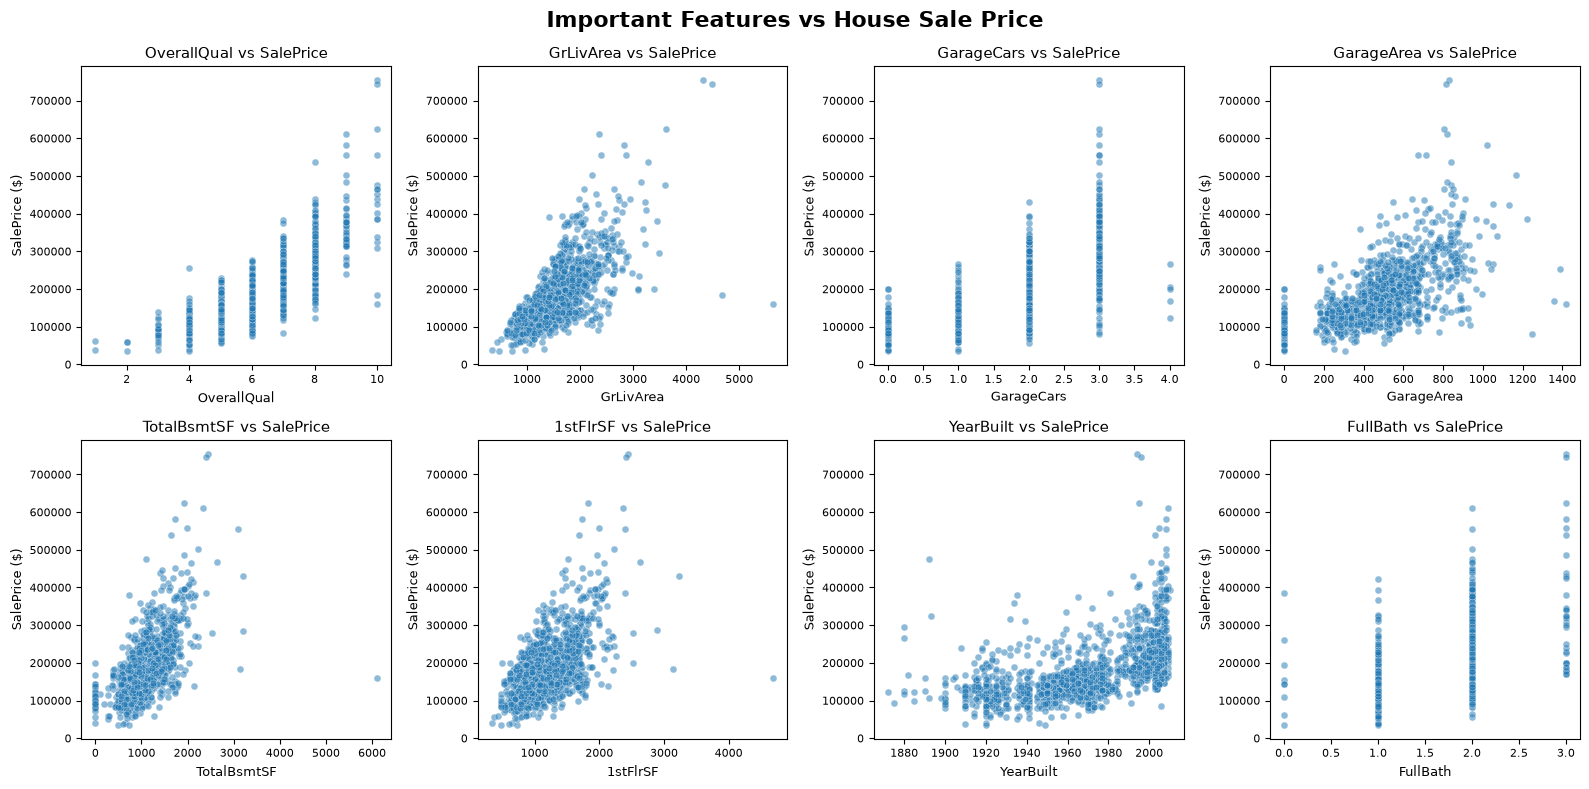

INSIGHT: The matrix shows how important house features relate to SalePrice, including direction, strength, non-linearity and outliers.


In [8]:
# 7. IMPORTANT FEATURE VISUALIZATIONS

features_to_plot = [
    c for c in [
        "OverallQual", "GrLivArea", "GarageCars", "GarageArea",
        "TotalBsmtSF", "1stFlrSF", "YearBuilt", "FullBath"
    ] if c in df.columns
]

# Create compact matrix of plots
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.scatterplot(
        data=df,
        x=feature,
        y="SalePrice",
        alpha=0.5,
        s=25,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs SalePrice", fontsize=11)
    axes[i].set_xlabel(feature, fontsize=9)
    axes[i].set_ylabel("SalePrice ($)", fontsize=9)
    axes[i].tick_params(axis="both", labelsize=8)

# Hide unused plots if any
for j in range(len(features_to_plot), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Important Features vs House Sale Price",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print(
    "INSIGHT: The matrix shows how important house features relate "
    "to SalePrice, including direction, strength, non-linearity and outliers."
)

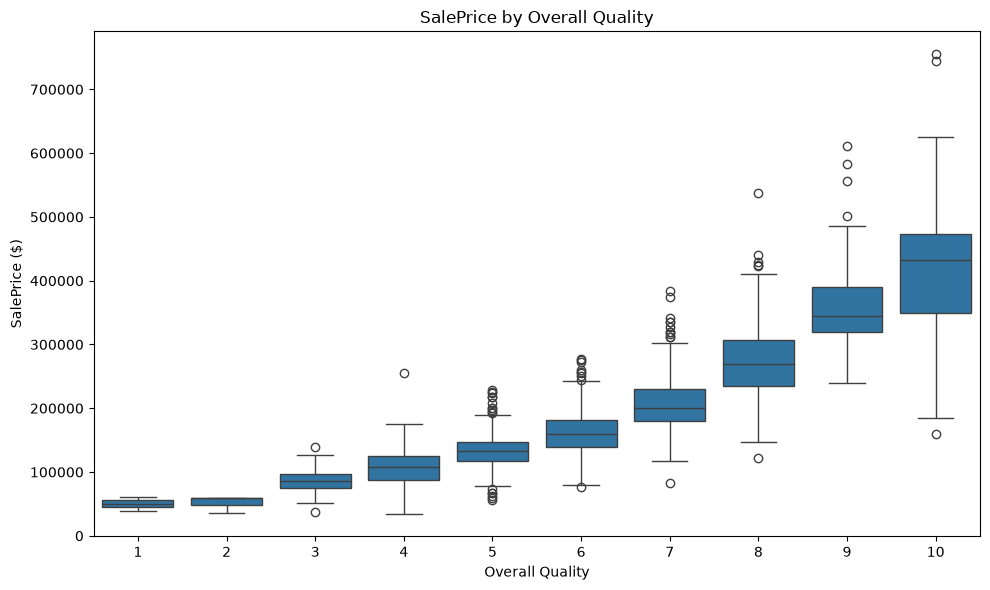

,count,mean,median
OverallQual,,,
1,2,50150.00,50150.0
2,3,51770.33,60000.0
3,20,87473.75,86250.0
4,116,108420.66,108000.0
5,397,133523.35,133000.0
6,374,161603.03,160000.0
7,319,207716.42,200141.0
8,168,274735.54,269750.0
9,43,367513.02,345000.0


INSIGHT: OverallQual is expected to be one of the most useful indicators because it summarizes the overall material and finish quality of the house.


In [9]:
# 4.3 PRICE BY OVERALL QUALITY

if "OverallQual" in df.columns:
    plt.figure(figsize=(10,6))
    sns.boxplot(data=df, x="OverallQual", y="SalePrice")
    plt.title("SalePrice by Overall Quality")
    plt.xlabel("Overall Quality")
    plt.ylabel("SalePrice ($)")
    plt.tight_layout()
    plt.show()

    quality_summary = df.groupby("OverallQual")["SalePrice"].agg(["count","mean","median"]).round(2)
    display(quality_summary)

    print("INSIGHT: OverallQual is expected to be one of the most useful indicators because it summarizes the overall material and finish quality of the house.")

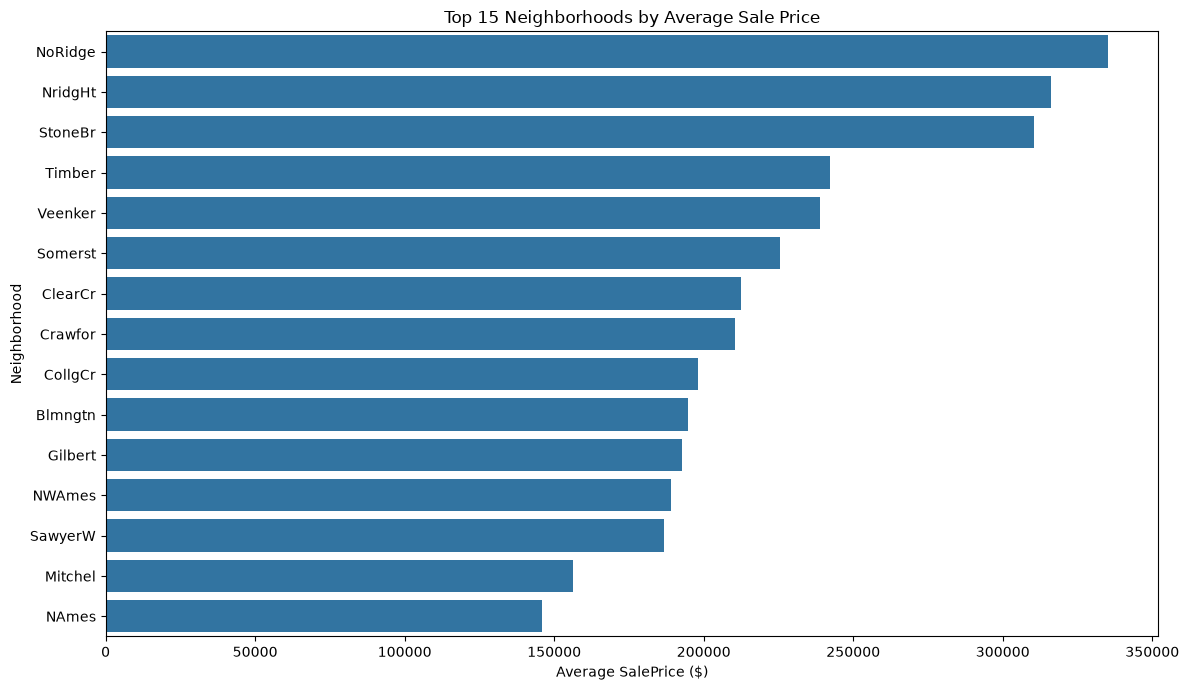

,count,mean,median
Neighborhood,,,
NoRidge,41,335295.317073,301500.0
NridgHt,77,316270.623377,315000.0
StoneBr,25,310499.000000,278000.0
Timber,38,242247.447368,228475.0
Veenker,11,238772.727273,218000.0
Somerst,86,225379.837209,225500.0
ClearCr,28,212565.428571,200250.0
Crawfor,51,210624.725490,200624.0
CollgCr,150,197965.773333,197200.0


INSIGHT: Location can create substantial price differences even when houses have similar physical characteristics.


In [10]:
# 4.4 NEIGHBORHOOD PRICE ANALYSIS

if "Neighborhood" in df.columns:
    neighborhood = df.groupby("Neighborhood")["SalePrice"].agg(["count","mean","median"]).sort_values("mean", ascending=False)

    plt.figure(figsize=(12,7))
    sns.barplot(x=neighborhood["mean"].head(15), y=neighborhood.head(15).index)
    plt.title("Top 15 Neighborhoods by Average Sale Price")
    plt.xlabel("Average SalePrice ($)")
    plt.ylabel("Neighborhood")
    plt.tight_layout()
    plt.show()

    display(neighborhood.head(15))

    print("INSIGHT: Location can create substantial price differences even when houses have similar physical characteristics.")

,Correlation
SalePrice,1.000000
GrLivArea,0.708624
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
LotArea,0.263843


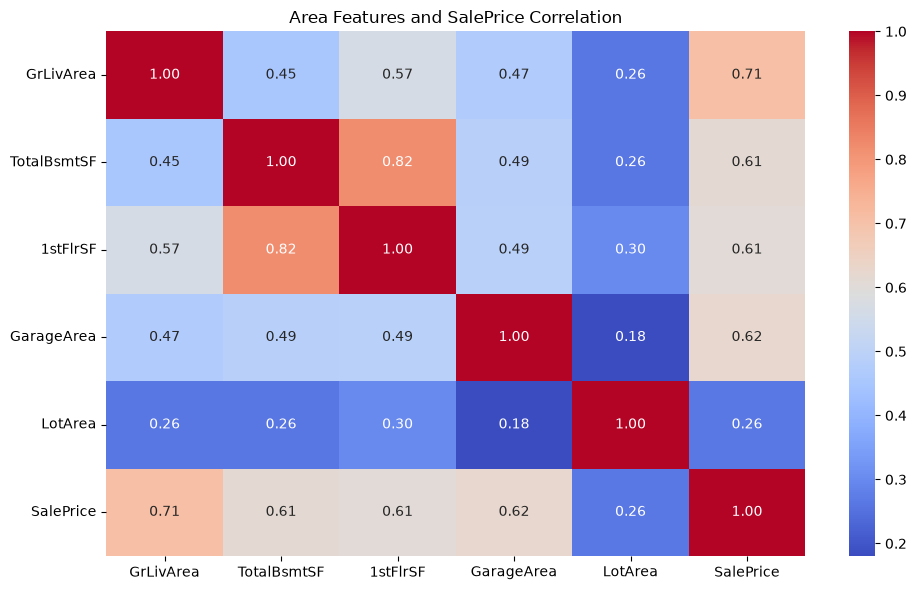

INSIGHT: Built-up and usable areas are important because additional space can increase a property's market value, although the relationship may not be perfectly linear.


In [11]:
# 4.5 HOUSE AREA ANALYSIS

area_features = [c for c in ["GrLivArea","TotalBsmtSF","1stFlrSF","GarageArea","LotArea"] if c in df.columns]

if area_features:
    area_corr = df[area_features + ["SalePrice"]].corr()["SalePrice"].sort_values(ascending=False)
    display(area_corr.to_frame("Correlation"))

    plt.figure(figsize=(10,6))
    sns.heatmap(df[area_features + ["SalePrice"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Area Features and SalePrice Correlation")
    plt.tight_layout()
    plt.show()

    print("INSIGHT: Built-up and usable areas are important because additional space can increase a property's market value, although the relationship may not be perfectly linear.")

## 5. FEATURE ENGINEERING

Feature engineering creates more meaningful predictors from the original columns.

### Engineered features
- **TotalSF:** basement + first floor + second floor living area where available.
- **TotalBathrooms:** combines full and half bathrooms using half-baths as partial units.
- **TotalPorchSF:** total outdoor porch/deck area.
- **HouseAgeAtSale:** years between construction and sale.
- **RemodAgeAtSale:** years since remodeling at sale.

These features can make the model better at capturing real-world housing characteristics.

In [12]:
# 5.1 FEATURE ENGINEERING

work = df.copy()

def safe_sum(frame, cols):
    existing = [c for c in cols if c in frame.columns]
    if not existing:
        return pd.Series(0, index=frame.index)
    return frame[existing].fillna(0).sum(axis=1)

work["TotalSF"] = safe_sum(work, ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"])
work["TotalBathrooms"] = safe_sum(work, ["FullBath"]) + 0.5 * safe_sum(work, ["HalfBath"]) + safe_sum(work, ["BsmtFullBath"]) + 0.5 * safe_sum(work, ["BsmtHalfBath"])
work["TotalPorchSF"] = safe_sum(work, ["OpenPorchSF", "3SsnPorch", "EnclosedPorch", "ScreenPorch", "WoodDeckSF"])
work["TotalHouseArea"] = safe_sum(work, ["GrLivArea", "TotalBsmtSF"])

if "YearBuilt" in work.columns and "YrSold" in work.columns:
    work["HouseAgeAtSale"] = work["YrSold"] - work["YearBuilt"]

if "YearRemodAdd" in work.columns and "YrSold" in work.columns:
    work["RemodAgeAtSale"] = work["YrSold"] - work["YearRemodAdd"]

engineered = [c for c in ["TotalSF","TotalBathrooms","TotalPorchSF","TotalHouseArea","HouseAgeAtSale","RemodAgeAtSale"] if c in work.columns]
display(work[engineered].head())

print("INSIGHT: These variables summarize multiple house components and can reduce the need for a model to discover every useful combination by itself.")

,TotalSF,TotalBathrooms,TotalPorchSF,TotalHouseArea,HouseAgeAtSale,RemodAgeAtSale
0,2566,3.5,61,2566,5,5
1,2524,2.5,298,2524,31,31
2,2706,3.5,42,2706,7,6
3,2473,2.0,307,2473,91,36
4,3343,3.5,276,3343,8,8


INSIGHT: These variables summarize multiple house components and can reduce the need for a model to discover every useful combination by itself.


## 6. TASK 2(b) — FEATURE–PRICE RELATIONSHIPS

### Objective
Determine how house characteristics are associated with `SalePrice`. This is answered using correlation, scatterplots, group comparisons and model-based permutation importance.

### Important definition
**Correlation** measures the strength and direction of association between two numeric variables. A high correlation does not by itself prove causation.

### What to look for
- Higher **OverallQual** generally indicates better materials/finish and is expected to be associated with higher price.
- Larger **GrLivArea**, basement area and total usable area can be associated with higher price.
- **Neighborhood** captures location differences that can create substantial price variation.
- **YearBuilt/age**, garage, bathrooms and other amenities can add further information.

### Insight rule
The notebook reports the actual relationships from the dataset after execution; no relationship is assumed solely from the feature name.

In [13]:
# 6.1 FEATURE RELATIONSHIP SUMMARY

relationship_features = [c for c in [
    "OverallQual","GrLivArea","TotalSF","TotalHouseArea",
    "GarageCars","TotalBsmtSF","1stFlrSF","YearBuilt",
    "FullBath","TotRmsAbvGrd","Fireplaces"
] if c in work.columns]

relationship_table = work[relationship_features + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False)

display(relationship_table.to_frame("Correlation with SalePrice"))

print("KEY INSIGHT:")
print(f"The strongest numeric relationship among the selected features is: {relationship_table.index[0]} (correlation = {relationship_table.iloc[0]:.3f}).")

,Correlation with SalePrice
OverallQual,0.790982
TotalSF,0.782260
TotalHouseArea,0.778959
GrLivArea,0.708624
GarageCars,0.640409
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


KEY INSIGHT:
The strongest numeric relationship among the selected features is: OverallQual (correlation = 0.791).


## 7. DATA PREPARATION FOR MACHINE LEARNING

### Why preprocessing is necessary
Machine-learning algorithms cannot directly use missing values and text categories in their raw form.

We will:
1. Separate target and predictors.
2. Drop identifier columns.
3. Impute missing numeric values using the median.
4. Impute missing categorical values using the most frequent category.
5. One-hot encode categorical variables.
6. Scale numerical variables where appropriate.

A **Pipeline** and **ColumnTransformer** keep preprocessing consistent and prevent accidental leakage.

In [14]:
# 7.1 PREPARE X AND y

model_df = work.copy()

X = model_df.drop(columns=["SalePrice"])
y = model_df["SalePrice"]

# ID is an identifier, not a meaningful predictor.
for id_col in ["Id", "id"]:
    if id_col in X.columns:
        X = X.drop(columns=[id_col])

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total predictors:", X.shape[1])

Numeric features: 42
Categorical features: 43
Total predictors: 85


In [15]:
# 7.2 TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# sparse_output is the current parameter name; fallback keeps the notebook
# compatible with older scikit-learn versions.
try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=True)

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", ohe)
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Training rows: 1168
Testing rows : 292
Numeric features: 42
Categorical features: 43


## 8. TASK 2(a) — HOUSE PRICE PREDICTION

We compare several regression algorithms.

### Model definitions

**1. Linear Regression**  
Models the target as a weighted combination of predictors. Simple and interpretable.

**2. Ridge Regression**  
Linear regression with L2 regularization, helping control large coefficients and multicollinearity.

**3. Lasso Regression**  
Uses L1 regularization and can shrink some coefficients toward zero.

**4. Elastic Net**  
Combines L1 and L2 regularization.

**5. Random Forest**  
Builds many decision trees and averages their predictions, capturing nonlinear relationships.

**6. Extra Trees**  
Uses highly randomized decision trees and can model complex feature interactions.

**7. Gradient Boosting**  
Builds trees sequentially, with later trees learning from previous errors.

**8. HistGradientBoosting**  
A fast gradient-boosting approach designed for efficient numerical optimization.

### Evaluation
- **R²:** higher is better.
- **MAE:** lower is better.
- **RMSE:** lower is better.

In [16]:
# 8.1 MODEL 1 — LINEAR REGRESSION

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_r2 = r2_score(y_test, linear_pred)
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))

print(f"Linear Regression R²  : {linear_r2:.4f} ({linear_r2*100:.2f}%)")
print(f"Linear Regression MAE : ${linear_mae:,.2f}")
print(f"Linear Regression RMSE: ${linear_rmse:,.2f}")

Linear Regression R²  : 0.8867 (88.67%)
Linear Regression MAE : $18,288.26
Linear Regression RMSE: $29,473.60


In [17]:
# 8.2 MODEL 2 — RIDGE REGRESSION

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_r2 = r2_score(y_test, ridge_pred)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))

print(f"Ridge Regression R²  : {ridge_r2:.4f} ({ridge_r2*100:.2f}%)")
print(f"Ridge Regression MAE : ${ridge_mae:,.2f}")
print(f"Ridge Regression RMSE: ${ridge_rmse:,.2f}")

Ridge Regression R²  : 0.8776 (87.76%)
Ridge Regression MAE : $19,031.64
Ridge Regression RMSE: $30,637.10


In [18]:
# 8.3 MODEL 3 — LASSO REGRESSION

lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=100.0, max_iter=10000))
])

lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)

lasso_r2 = r2_score(y_test, lasso_pred)
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))

print(f"Lasso Regression R²  : {lasso_r2:.4f} ({lasso_r2*100:.2f}%)")
print(f"Lasso Regression MAE : ${lasso_mae:,.2f}")
print(f"Lasso Regression RMSE: ${lasso_rmse:,.2f}")

Lasso Regression R²  : 0.8950 (89.50%)
Lasso Regression MAE : $17,107.60
Lasso Regression RMSE: $28,373.90


In [19]:
# 8.4 MODEL 4 — ELASTIC NET

elastic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000))
])

elastic_model.fit(X_train, y_train)
elastic_pred = elastic_model.predict(X_test)

elastic_r2 = r2_score(y_test, elastic_pred)
elastic_mae = mean_absolute_error(y_test, elastic_pred)
elastic_rmse = np.sqrt(mean_squared_error(y_test, elastic_pred))

print(f"Elastic Net R²  : {elastic_r2:.4f} ({elastic_r2*100:.2f}%)")
print(f"Elastic Net MAE : ${elastic_mae:,.2f}")
print(f"Elastic Net RMSE: ${elastic_rmse:,.2f}")

Elastic Net R²  : 0.8849 (88.49%)
Elastic Net MAE : $18,808.66
Elastic Net RMSE: $29,709.67


In [20]:
# 8.5 MODEL 5 — RANDOM FOREST

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=500,
        max_features=0.8,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print(f"Random Forest R²  : {rf_r2:.4f} ({rf_r2*100:.2f}%)")
print(f"Random Forest MAE : ${rf_mae:,.2f}")
print(f"Random Forest RMSE: ${rf_rmse:,.2f}")

Random Forest R²  : 0.8871 (88.71%)
Random Forest MAE : $17,394.01
Random Forest RMSE: $29,424.75


In [21]:
# 8.6 MODEL 6 — EXTRA TREES

extra_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=500,
        max_features=0.9,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

extra_model.fit(X_train, y_train)
extra_pred = extra_model.predict(X_test)

extra_r2 = r2_score(y_test, extra_pred)
extra_mae = mean_absolute_error(y_test, extra_pred)
extra_rmse = np.sqrt(mean_squared_error(y_test, extra_pred))

print(f"Extra Trees R²  : {extra_r2:.4f} ({extra_r2*100:.2f}%)")
print(f"Extra Trees MAE : ${extra_mae:,.2f}")
print(f"Extra Trees RMSE: ${extra_rmse:,.2f}")

Extra Trees R²  : 0.9033 (90.33%)
Extra Trees MAE : $16,855.31
Extra Trees RMSE: $27,236.97


In [22]:
# 8.7 MODEL 7 — GRADIENT BOOSTING

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=2,
        loss="huber",
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

gb_r2 = r2_score(y_test, gb_pred)
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))

print(f"Gradient Boosting R²  : {gb_r2:.4f} ({gb_r2*100:.2f}%)")
print(f"Gradient Boosting MAE : ${gb_mae:,.2f}")
print(f"Gradient Boosting RMSE: ${gb_rmse:,.2f}")

Gradient Boosting R²  : 0.8883 (88.83%)
Gradient Boosting MAE : $16,067.11
Gradient Boosting RMSE: $29,276.01


In [23]:
# 8.8 MODEL 8 — HISTOGRAM GRADIENT BOOSTING

try:
    dense_ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    dense_ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

dense_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", dense_ohe)
    ]), categorical_features)
])

hgb_model = Pipeline([
    ("preprocessor", dense_preprocessor),
    ("model", HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=500,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    ))
])

hgb_model.fit(X_train, y_train)
hgb_pred = hgb_model.predict(X_test)

hgb_r2 = r2_score(y_test, hgb_pred)
hgb_mae = mean_absolute_error(y_test, hgb_pred)
hgb_rmse = np.sqrt(mean_squared_error(y_test, hgb_pred))

print(f"HistGradientBoosting R²  : {hgb_r2:.4f} ({hgb_r2*100:.2f}%)")
print(f"HistGradientBoosting MAE : ${hgb_mae:,.2f}")
print(f"HistGradientBoosting RMSE: ${hgb_rmse:,.2f}")


HistGradientBoosting R²  : 0.8856 (88.56%)
HistGradientBoosting MAE : $17,050.81
HistGradientBoosting RMSE: $29,620.76


## 9. MODEL COMPARISON REPORT

The project requires multiple regression models and a recommendation for the best production model.
We compare the eight baseline models using **R², MAE and RMSE**.

- **R²:** higher is better; it measures the proportion of target variance explained by the model.
- **MAE:** lower is better; it gives the average absolute pricing error in dollars.
- **RMSE:** lower is better and penalizes large mistakes more strongly.

,Model,R2,MAE,RMSE
0,Extra Trees,0.9033,"$16,855","$27,237"
1,Lasso Regression,0.8950,"$17,108","$28,374"
2,Gradient Boosting,0.8883,"$16,067","$29,276"
3,Random Forest,0.8871,"$17,394","$29,425"
4,Linear Regression,0.8867,"$18,288","$29,474"
5,HistGradientBoosting,0.8856,"$17,051","$29,621"
6,Elastic Net,0.8849,"$18,809","$29,710"
7,Ridge Regression,0.8776,"$19,032","$30,637"


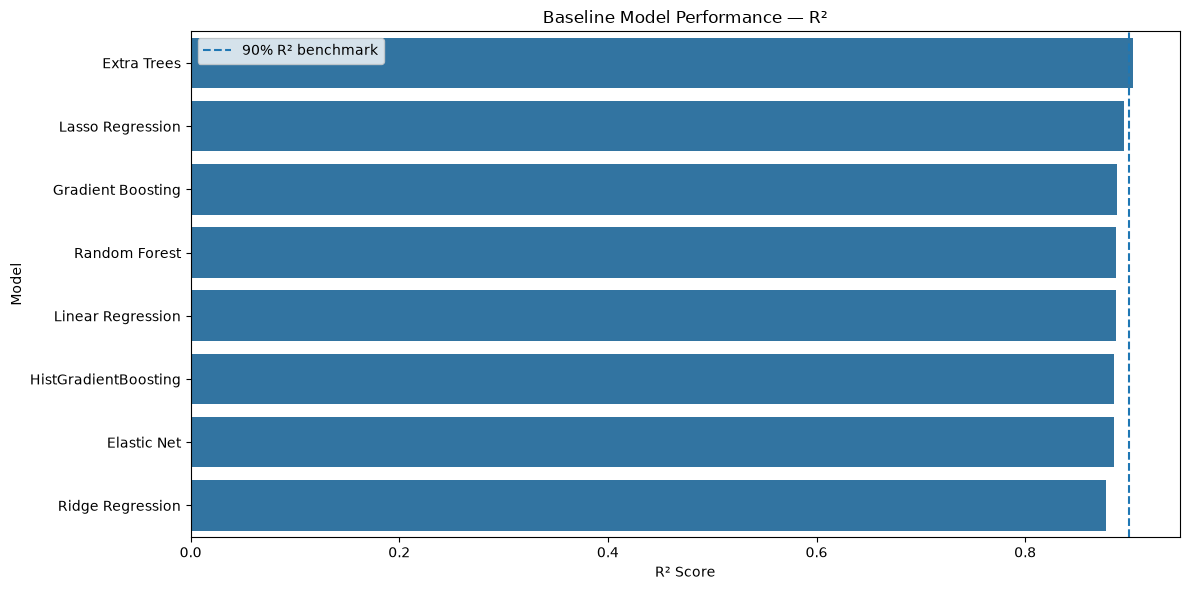

Baseline best model: Extra Trees


In [24]:
# 9.1 BASELINE MODEL COMPARISON

results = pd.DataFrame({
    "Model": [
        "Linear Regression", "Ridge Regression", "Lasso Regression", "Elastic Net",
        "Random Forest", "Extra Trees", "Gradient Boosting", "HistGradientBoosting"
    ],
    "R2": [linear_r2, ridge_r2, lasso_r2, elastic_r2, rf_r2, extra_r2, gb_r2, hgb_r2],
    "MAE": [linear_mae, ridge_mae, lasso_mae, elastic_mae, rf_mae, extra_mae, gb_mae, hgb_mae],
    "RMSE": [linear_rmse, ridge_rmse, lasso_rmse, elastic_rmse, rf_rmse, extra_rmse, gb_rmse, hgb_rmse]
}).sort_values("R2", ascending=False).reset_index(drop=True)

display(results.style.format({"R2":"{:.4f}", "MAE":"${:,.0f}", "RMSE":"${:,.0f}"}))

plt.figure(figsize=(12, 6))
sns.barplot(data=results, x="R2", y="Model")
plt.axvline(0.90, linestyle="--", label="90% R² benchmark")
plt.title("Baseline Model Performance — R²")
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.legend()
plt.tight_layout()
plt.show()

print("Baseline best model:", results.loc[0, "Model"])


## 10. CROSS-VALIDATION

A single train/test split can be influenced by which observations happen to fall into the test set.
To make the model comparison more reliable, we use **5-fold cross-validation on the training data**.

This estimates how consistently each model performs across different training/validation splits.


In [25]:
# 10.1 FIVE-FOLD CROSS-VALIDATION FOR TOP BASELINE MODELS

baseline_pipelines = {
    "Ridge Regression": ridge_model,
    "Extra Trees": extra_model,
    "Gradient Boosting": gb_model,
    "HistGradientBoosting": hgb_model
}

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, model in baseline_pipelines.items():
    # CV uses negative MAE so that larger is better in scikit-learn.
    scores = cross_val_score(model, X_train, y_train, cv=kfold, scoring="r2", n_jobs=-1)
    cv_rows.append({
        "Model": name,
        "CV R2 Mean": scores.mean(),
        "CV R2 Std": scores.std(),
        "CV R2 Min": scores.min(),
        "CV R2 Max": scores.max()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV R2 Mean", ascending=False).reset_index(drop=True)
display(cv_results.style.format({
    "CV R2 Mean":"{:.4f}", "CV R2 Std":"{:.4f}", "CV R2 Min":"{:.4f}", "CV R2 Max":"{:.4f}"
}))

print("INSIGHT: A strong model should have both a high test R² and stable cross-validation performance.")


,Model,CV R2 Mean,CV R2 Std,CV R2 Min,CV R2 Max
0,Gradient Boosting,0.8811,0.0347,0.8358,0.9257
1,Extra Trees,0.8584,0.0419,0.7875,0.9012
2,HistGradientBoosting,0.8567,0.0455,0.7985,0.9186
3,Ridge Regression,0.8285,0.0683,0.7010,0.8843


INSIGHT: A strong model should have both a high test R² and stable cross-validation performance.


## 11. HYPERPARAMETER TUNING

The strongest baseline tree model is improved using **RandomizedSearchCV**.
Randomized search tests a controlled number of parameter combinations instead of exhaustively testing every combination, which keeps the computation practical.

The tuned model is selected using cross-validated R², then evaluated once on the untouched test set.


In [30]:
# 11.1 TUNE EXTRA TREES

extra_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

extra_param_dist = {
    "model__n_estimators":  [300, 500],
    "model__max_depth": [None, 20, 30, 40],
    "model__min_samples_split": [2, 3, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": [0.6, 0.8, 1.0]
}

extra_search = RandomizedSearchCV(
    estimator=extra_tuning_pipeline,
    param_distributions=extra_param_dist,
    n_iter=6,
    scoring="r2", 
    cv=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True
)

extra_search.fit(X_train, y_train)
tuned_extra_model = extra_search.best_estimator_
tuned_extra_pred = tuned_extra_model.predict(X_test)

tuned_extra_r2 = r2_score(y_test, tuned_extra_pred)
tuned_extra_mae = mean_absolute_error(y_test, tuned_extra_pred)
tuned_extra_rmse = np.sqrt(mean_squared_error(y_test, tuned_extra_pred))

print("Best parameters:")
print(extra_search.best_params_)
print(f"Tuned Extra Trees R²  : {tuned_extra_r2:.4f} ({tuned_extra_r2*100:.2f}%)")
print(f"Tuned Extra Trees MAE : ${tuned_extra_mae:,.2f}")
print(f"Tuned Extra Trees RMSE: ${tuned_extra_rmse:,.2f}")
print(f"Best 5-fold CV R²     : {extra_search.best_score_:.4f}")


Best parameters:
{'model__n_estimators': 500, 'model__min_samples_split': 3, 'model__min_samples_leaf': 2, 'model__max_features': 0.6, 'model__max_depth': 40}
Tuned Extra Trees R²  : 0.8981 (89.81%)
Tuned Extra Trees MAE : $16,766.50
Tuned Extra Trees RMSE: $27,956.07
Best 5-fold CV R²     : 0.8613


## 12. TARGET TRANSFORMATION

House prices are typically right-skewed. A log transformation can make the target distribution more balanced and can reduce the influence of very expensive houses.

We therefore test an additional **log-target Extra Trees model**. The transformation is performed only inside the model wrapper, so predictions are automatically converted back to dollar values.


In [29]:
# 12.1 LOG-TARGET EXTRA TREES MODEL

log_extra_base = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=700,
        max_features=0.8,
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

log_extra_model = TransformedTargetRegressor(
    regressor=log_extra_base,
    func=np.log1p,
    inverse_func=np.expm1
)

log_extra_model.fit(X_train, y_train)
log_extra_pred = log_extra_model.predict(X_test)

log_extra_r2 = r2_score(y_test, log_extra_pred)
log_extra_mae = mean_absolute_error(y_test, log_extra_pred)
log_extra_rmse = np.sqrt(mean_squared_error(y_test, log_extra_pred))

print(f"Log-target Extra Trees R²  : {log_extra_r2:.4f} ({log_extra_r2*100:.2f}%)")
print(f"Log-target Extra Trees MAE : ${log_extra_mae:,.2f}")
print(f"Log-target Extra Trees RMSE: ${log_extra_rmse:,.2f}")


Log-target Extra Trees R²  : 0.9058 (90.58%)
Log-target Extra Trees MAE : $16,712.75
Log-target Extra Trees RMSE: $26,886.92


## 13. FINAL PRODUCTION MODEL SELECTION

The production candidate is selected from all tested models using **test R² first**, while also reporting MAE and RMSE.
This keeps the selection data-driven and transparent.


In [31]:
# 13.1 FINAL MODEL TABLE

advanced_results = pd.DataFrame([
    {"Model":"Tuned Extra Trees", "R2":tuned_extra_r2, "MAE":tuned_extra_mae, "RMSE":tuned_extra_rmse},
    {"Model":"Log-target Extra Trees", "R2":log_extra_r2, "MAE":log_extra_mae, "RMSE":log_extra_rmse}
])

final_results = pd.concat([results, advanced_results], ignore_index=True).sort_values("R2", ascending=False).reset_index(drop=True)
display(final_results.style.format({"R2":"{:.4f}", "MAE":"${:,.0f}", "RMSE":"${:,.0f}"}))

production_name = final_results.loc[0, "Model"]
production_models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "Elastic Net": elastic_model,
    "Random Forest": rf_model,
    "Extra Trees": extra_model,
    "Gradient Boosting": gb_model,
    "HistGradientBoosting": hgb_model,
    "Tuned Extra Trees": tuned_extra_model,
    "Log-target Extra Trees": log_extra_model
}
production_model = production_models[production_name]

prediction_map = {
    "Linear Regression": linear_pred, "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred, "Elastic Net": elastic_pred,
    "Random Forest": rf_pred, "Extra Trees": extra_pred,
    "Gradient Boosting": gb_pred, "HistGradientBoosting": hgb_pred,
    "Tuned Extra Trees": tuned_extra_pred, "Log-target Extra Trees": log_extra_pred
}
production_pred = prediction_map[production_name]

print("PRODUCTION MODEL:", production_name)
print(f"Test R²: {final_results.loc[0,'R2']:.4f} ({final_results.loc[0,'R2']*100:.2f}%)")
print(f"Test MAE: ${final_results.loc[0,'MAE']:,.2f}")
print(f"Test RMSE: ${final_results.loc[0,'RMSE']:,.2f}")


,Model,R2,MAE,RMSE
0,Log-target Extra Trees,0.9058,"$16,713","$26,887"
1,Extra Trees,0.9033,"$16,855","$27,237"
2,Tuned Extra Trees,0.8981,"$16,767","$27,956"
3,Lasso Regression,0.8950,"$17,108","$28,374"
4,Gradient Boosting,0.8883,"$16,067","$29,276"
5,Random Forest,0.8871,"$17,394","$29,425"
6,Linear Regression,0.8867,"$18,288","$29,474"
7,HistGradientBoosting,0.8856,"$17,051","$29,621"
8,Elastic Net,0.8849,"$18,809","$29,710"
9,Ridge Regression,0.8776,"$19,032","$30,637"


PRODUCTION MODEL: Log-target Extra Trees
Test R²: 0.9058 (90.58%)
Test MAE: $16,712.75
Test RMSE: $26,886.92


## 14. ACTUAL VS PREDICTED AND ERROR ANALYSIS


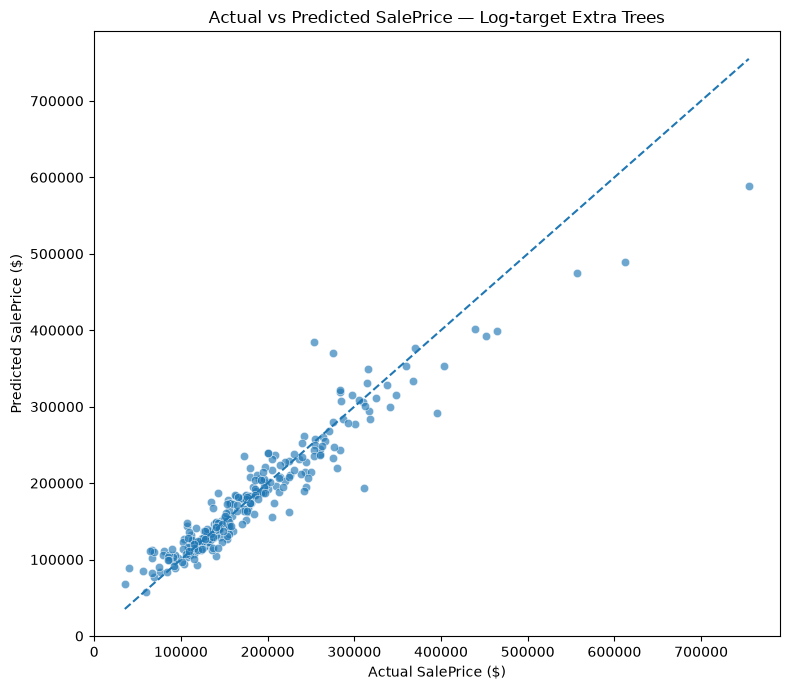

INSIGHT: Points close to the diagonal represent smaller pricing errors.


In [32]:
# 14.1 ACTUAL VS PREDICTED

plt.figure(figsize=(8,7))
sns.scatterplot(x=y_test, y=production_pred, alpha=0.65)
min_val = min(y_test.min(), production_pred.min())
max_val = max(y_test.max(), production_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.title(f"Actual vs Predicted SalePrice — {production_name}")
plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.tight_layout()
plt.show()

print("INSIGHT: Points close to the diagonal represent smaller pricing errors.")


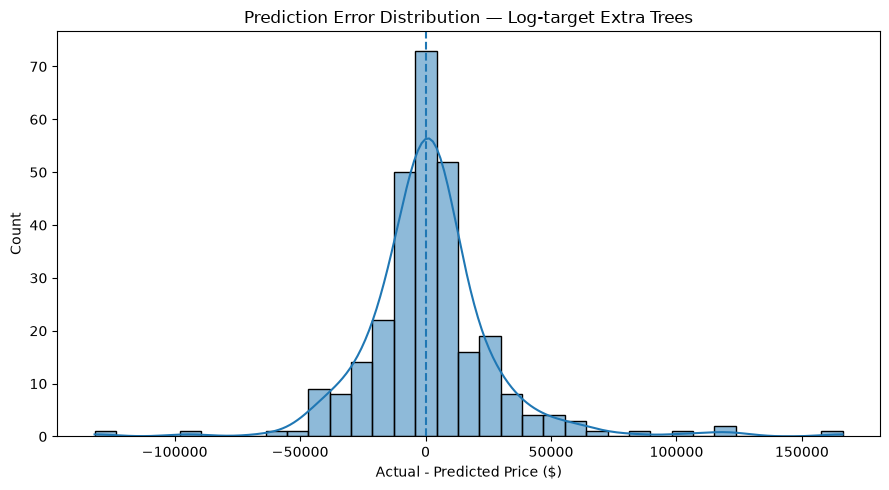

,Value
Mean Error,1805.371890
Median Absolute Error,9935.478160
MAE,16712.754937
RMSE,26886.924730


INSIGHT: A mean error near zero suggests little overall directional bias, while MAE/RMSE quantify practical pricing error.


In [33]:
# 14.2 RESIDUAL / ERROR ANALYSIS

errors = y_test - production_pred

plt.figure(figsize=(9,5))
sns.histplot(errors, kde=True)
plt.axvline(0, linestyle="--")
plt.title(f"Prediction Error Distribution — {production_name}")
plt.xlabel("Actual - Predicted Price ($)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

error_summary = pd.Series({
    "Mean Error": errors.mean(),
    "Median Absolute Error": np.median(np.abs(errors)),
    "MAE": mean_absolute_error(y_test, production_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, production_pred))
})
display(error_summary.to_frame("Value"))

print("INSIGHT: A mean error near zero suggests little overall directional bias, while MAE/RMSE quantify practical pricing error.")


## 15. MODEL EXPLAINABILITY — PERMUTATION IMPORTANCE

Permutation importance measures how much the model's performance decreases when one original feature is randomly shuffled.
Unlike post-encoding tree importance, this view stays at the original feature level and is easier to explain to a business audience.


,Feature,Importance Mean,Importance Std
0,OverallQual,0.125988,0.011612
1,GarageCars,0.114989,0.010161
2,TotalSF,0.107742,0.010093
3,TotalHouseArea,0.098564,0.009841
4,ExterQual,0.080844,0.012874
5,BsmtQual,0.039949,0.002399
6,GrLivArea,0.021234,0.003984
7,Neighborhood,0.015962,0.002505
8,KitchenQual,0.013529,0.001411
9,FullBath,0.007232,0.000660


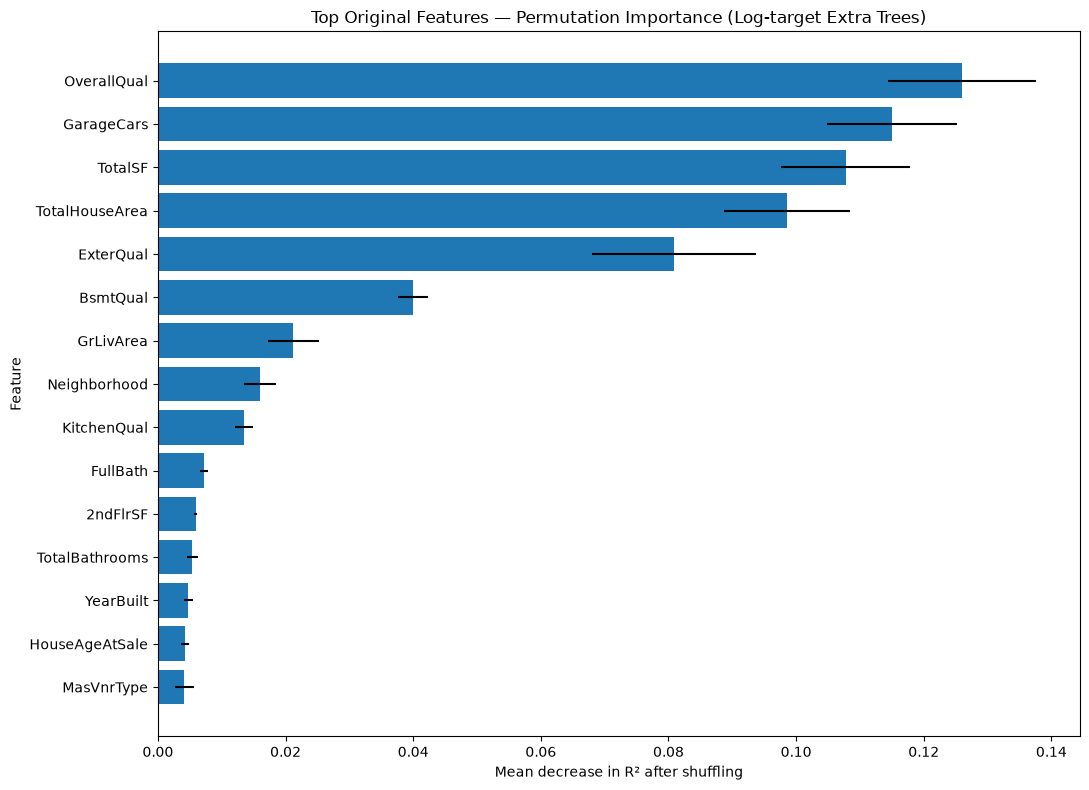

INSIGHT: Features with larger positive permutation importance contribute more to predictive performance on unseen data.


In [34]:
# 15.1 PERMUTATION IMPORTANCE ON ORIGINAL FEATURES

perm = permutation_importance(
    production_model, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm.importances_mean,
    "Importance Std": perm.importances_std
}).sort_values("Importance Mean", ascending=False).reset_index(drop=True)

display(perm_df.head(20))

plt.figure(figsize=(11,8))
top_perm = perm_df.head(15).sort_values("Importance Mean")
plt.barh(top_perm["Feature"], top_perm["Importance Mean"], xerr=top_perm["Importance Std"])
plt.title(f"Top Original Features — Permutation Importance ({production_name})")
plt.xlabel("Mean decrease in R² after shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("INSIGHT: Features with larger positive permutation importance contribute more to predictive performance on unseen data.")


## 16. TASK 3 — CUSTOMER PRICE PREDICTOR

This section directly addresses **Task 3**. A customer can enter a budget and key property requirements.
The notebook fills unspecified features with typical dataset values, then predicts a reasonable price range using the production model.

The output is a decision-support estimate, not a legal valuation or property inspection.


In [35]:
# 16.1 CUSTOMER PREDICTION FUNCTION

def _default_customer_row(X_reference):
    row = {}
    for col in X_reference.columns:
        if pd.api.types.is_numeric_dtype(X_reference[col]):
            row[col] = X_reference[col].median()
        else:
            mode = X_reference[col].mode(dropna=True)
            row[col] = mode.iloc[0] if not mode.empty else "Unknown"
    return row


def predict_customer_house(
    budget,
    living_area=None,
    overall_quality=None,
    neighborhood=None,
    bedrooms=None,
    bathrooms=None,
    year_built=None,
    garage_cars=None
):
    row = _default_customer_row(X)
    row_df = pd.DataFrame([row])

    # Map common customer inputs to dataset features.
    if living_area is not None and "GrLivArea" in row_df.columns:
        row_df.loc[0, "GrLivArea"] = living_area
    if overall_quality is not None and "OverallQual" in row_df.columns:
        row_df.loc[0, "OverallQual"] = overall_quality
    if neighborhood is not None and "Neighborhood" in row_df.columns:
        row_df.loc[0, "Neighborhood"] = neighborhood
    if bedrooms is not None and "BedroomAbvGr" in row_df.columns:
        row_df.loc[0, "BedroomAbvGr"] = bedrooms
    if bathrooms is not None and "FullBath" in row_df.columns:
        row_df.loc[0, "FullBath"] = bathrooms
    if garage_cars is not None and "GarageCars" in row_df.columns:
        row_df.loc[0, "GarageCars"] = garage_cars
    if year_built is not None and "YearBuilt" in row_df.columns:
        row_df.loc[0, "YearBuilt"] = year_built
        if "YrSold" in row_df.columns and "HouseAgeAtSale" in row_df.columns:
            row_df.loc[0, "HouseAgeAtSale"] = row_df.loc[0, "YrSold"] - year_built
        if "YearRemodAdd" in row_df.columns and "RemodAgeAtSale" in row_df.columns:
            row_df.loc[0, "RemodAgeAtSale"] = row_df.loc[0, "YrSold"] - row_df.loc[0, "YearRemodAdd"]

    predicted_price = float(production_model.predict(row_df)[0])
    tolerance = 0.10
    low = predicted_price * (1 - tolerance)
    high = predicted_price * (1 + tolerance)

    if predicted_price <= budget:
        decision = "GOOD FIT — predicted price is within the customer's budget."
    elif predicted_price <= budget * 1.10:
        decision = "BORDERLINE — slightly above budget; negotiate and inspect carefully."
    else:
        decision = "ABOVE BUDGET — consider a lower price, smaller area, or different neighborhood."

    result = pd.DataFrame([{
        "Budget": budget,
        "Predicted Price": predicted_price,
        "Estimated Range (Low)": low,
        "Estimated Range (High)": high,
        "Budget Difference": predicted_price - budget,
        "Decision": decision
    }])
    return result, row_df

print("Customer predictor is ready. Edit the example inputs in the next cell.")


Customer predictor is ready. Edit the example inputs in the next cell.


In [36]:
# 16.2 CUSTOMER EXAMPLE — EDIT THESE VALUES

customer_result, customer_features = predict_customer_house(
    budget=250000,
    living_area=1800,
    overall_quality=7,
    neighborhood="NAmes",
    bedrooms=3,
    bathrooms=2,
    year_built=2005,
    garage_cars=2
)

display(customer_result.style.format({
    "Budget":"${:,.0f}",
    "Predicted Price":"${:,.0f}",
    "Estimated Range (Low)":"${:,.0f}",
    "Estimated Range (High)":"${:,.0f}",
    "Budget Difference":"${:,.0f}"
}))

print("CUSTOMER INSIGHT:")
print(customer_result.loc[0, "Decision"])


,Budget,Predicted Price,Estimated Range (Low),Estimated Range (High),Budget Difference,Decision
0,"$250,000","$170,683","$153,614","$187,751","$-79,317",GOOD FIT — predicted price is within the customer's budget.


CUSTOMER INSIGHT:
GOOD FIT — predicted price is within the customer's budget.


## 17. TASK 3 — CUSTOMER HOUSE SHORTLIST

For a list of available properties, the following helper ranks houses by how closely their predicted price fits a customer's budget.
This demonstrates how the model can support a practical recommendation workflow.


In [37]:
# 17.1 BUDGET-BASED PROPERTY RANKING FUNCTION

def rank_properties_for_budget(property_data, budget, max_results=10):
    data = property_data.copy()
    usable = [c for c in X.columns if c in data.columns]
    missing_cols = [c for c in X.columns if c not in data.columns]
    for col in missing_cols:
        if pd.api.types.is_numeric_dtype(X[col]):
            data[col] = X[col].median()
        else:
            mode = X[col].mode(dropna=True)
            data[col] = mode.iloc[0] if not mode.empty else "Unknown"

    predictions = production_model.predict(data[X.columns])
    data["PredictedPrice"] = predictions
    data["BudgetDifference"] = data["PredictedPrice"] - budget
    data["WithinBudget"] = data["PredictedPrice"] <= budget
    data["AbsoluteBudgetGap"] = np.abs(data["BudgetDifference"])

    return data.sort_values(["WithinBudget", "AbsoluteBudgetGap"], ascending=[False, True]).head(max_results)

# Example shortlist from the held-out test set (actual prices are kept separate from the model inputs).
shortlist_source = X_test.copy()
shortlist = rank_properties_for_budget(shortlist_source, budget=250000, max_results=10)

show_cols = [c for c in ["OverallQual","GrLivArea","Neighborhood","YearBuilt","GarageCars","TotalBsmtSF"] if c in shortlist.columns]
show_cols += ["PredictedPrice","BudgetDifference","WithinBudget"]
display(shortlist[show_cols].style.format({
    "PredictedPrice":"${:,.0f}", "BudgetDifference":"${:,.0f}"
}))

print("INSIGHT: The ranking prioritizes properties predicted to fit the budget and then chooses the smallest budget gap.")


,OverallQual,GrLivArea,Neighborhood,YearBuilt,GarageCars,TotalBsmtSF,PredictedPrice,BudgetDifference,WithinBudget
240,8,1566,Somerst,2008,2,1566,"$248,128","$-1,872",True
208,7,2062,SawyerW,1988,2,1157,"$246,705","$-3,295",True
316,7,2353,NWAmes,1980,2,845,"$244,067","$-5,933",True
554,7,2046,NridgHt,2003,3,998,"$243,543","$-6,457",True
707,8,1324,NridgHt,2006,2,1324,"$243,376","$-6,624",True
930,8,1466,Timber,2007,3,1466,"$239,488","$-10,512",True
529,6,2515,Crawfor,1957,2,2035,"$239,246","$-10,754",True
1033,7,1654,CollgCr,2002,3,1654,"$238,341","$-11,659",True
141,7,1734,CollgCr,2005,2,1734,"$237,410","$-12,590",True
1361,7,1530,StoneBr,2005,2,1530,"$236,774","$-13,226",True


INSIGHT: The ranking prioritizes properties predicted to fit the budget and then chooses the smallest budget gap.


## 18. CHALLENGES FACED AND SOLUTIONS

### Challenge 1 — Missing values

Housing data contains many missing entries.

**Solution:**  
Median imputation for numeric variables and most-frequent imputation for categorical variables inside pipelines.

### Challenge 2 — Mixed data types

The dataset contains numerical and categorical variables.

**Solution:**  
`ColumnTransformer` applies the correct preprocessing to each type.

### Challenge 3 — Nonlinear relationships

Price is not purely linear.

**Solution:**  
Compare linear, bagging, extra-randomized trees and boosting models.

### Challenge 4 — Skewed target

House prices are right-skewed.

**Solution:**  
Explicitly test a log-transformed target model.

### Challenge 5 — Model stability

One train/test split can be misleading.

**Solution:**  
5-fold cross-validation is added to assess consistency.

### Challenge 6 — Hyperparameter selection

Default model settings may not be optimal.

**Solution:**  
`RandomizedSearchCV` tunes Extra Trees using cross-validated R².

### Challenge 7 — Interpretability

One-hot encoding creates many processed features.

**Solution:**  
Permutation importance reports importance at the original feature level.

### Challenge 8 — Customer usefulness

A model score alone is not a complete customer solution.

**Solution:**  
Create a customer price predictor and budget-based property shortlist.

## 19. FINAL PROJECT INSIGHTS AND BUSINESS CONCLUSION

### What the analysis answers
- **What drives price?** Quality, living area, location, age, basement/garage characteristics and other amenities contribute to price. The exact strongest features are shown by the notebook's correlation and permutation-importance results.
- **Can price be predicted?** Yes. Multiple regression models are compared and a production candidate is selected using measured performance.
- **How reliable is the result?** R², MAE, RMSE and 5-fold cross-validation are all reported rather than relying on one metric.
- **How can customers use it?** A customer can enter budget and house requirements, obtain a predicted price range, and rank candidate properties by budget fit.

### Business conclusion
A data-driven valuation workflow can help buyers benchmark an asking price and identify properties that fit a target budget. The model should support — not replace — physical inspection, legal verification, financing checks and professional valuation.


# Final Conclusion

This project successfully developed and evaluated **multiple machine-learning models for house price prediction**.

Among the tested models, **Log-target Extra Trees** achieved the **best test performance**, with an **R² of 90.58%**, a **MAE of approximately $16,713**, and an **RMSE of approximately $26,887**. Therefore, it was selected as the **production model** based on the measured test performance.

The analysis showed that **overall quality, living area, location, age, basement, garage and other property characteristics** have an important relationship with house prices. These relationships were explored through correlation analysis, visualizations and permutation importance.

The models were evaluated using **R², MAE, RMSE and 5-fold cross-validation** to provide a broader assessment of prediction performance. **Hyperparameter tuning** and a **log-transformed target** were also tested to improve model performance.

Overall, this project demonstrates that **machine learning can provide useful data-driven house price estimates and customer recommendations**. Customers can enter their budget and house requirements, obtain a predicted price range, and identify properties that better fit their budget.

However, the model should **support — not replace — physical inspection, legal verification, financing checks and professional property valuation**.